# Trajectory analysis of all seven neighborhood classes

In [1]:
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd
import scFates as scf
from scipy.stats import spearmanr, kendalltau, pearsonr
import seaborn as sns
# import tqdm
from Xenium_5K_IPF_constants import WORK_PATH, EPITHELIAL_SUBTYPE

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

REV_PATH=f"{WORK_PATH}Revision/104/"
os.makedirs(REV_PATH, exist_ok=True)

In [2]:
n_adata = sc.read_h5ad(f"{WORK_PATH}AnnData/EcNP.h5ad")
n_adata.obs["subtype"]=pd.Categorical(n_adata.obs["subtype"], categories=EPITHELIAL_SUBTYPE, ordered=True)

In [3]:
# scFate
scf.tl.curve(n_adata,Nodes=30,use_rep="X_pca",ndims_rep=2,epg_lambda=0.1, epg_mu=1)

inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1
    finished (0:00:06) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.


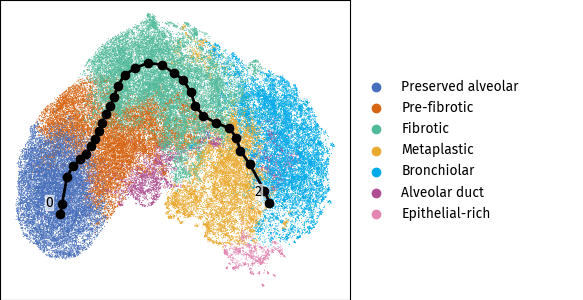

In [4]:
fig, ax = plt.subplots(figsize=(3.5/0.6,3))
fig.subplots_adjust(left=0, right=0.6, top=1, bottom=0)
scf.pl.graph(n_adata,basis="umap", color_cells="EcNP", s=2, ax=ax)
for obj in ax.get_children():
    if hasattr(obj, "get_text") and obj.get_text() in {"0", "2"}:
        obj.set_fontsize(16)
plt.title("")
plt.axis("off")
ax.legend(title="", loc='upper left', bbox_to_anchor=(0.92, 0.98), edgecolor="white", labelcolor="black", markerscale=1.5, fontsize=13, title_fontsize=13, handletextpad=0.05)
plt.savefig(f"{REV_PATH}EcNP_umap_cPosition_tree_allclass.png", dpi=500, format="png", bbox_inches=None)

In [5]:
scf.tl.root(n_adata,0)

node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [6]:
scf.tl.pseudotime(n_adata,n_jobs=20,n_map=20,seed=1)

projecting cells onto the principal graph
    mappings: 100%|█████████████████████████████████████████████████████████████████████| 20/20 [00:57<00:00,  2.88s/it]
    finished (0:01:07) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [7]:
# max_min scaling
t = n_adata.obs["t"].values
n_adata.obs["t"] = (t - np.min(t)) / (np.max(t) - np.min(t))

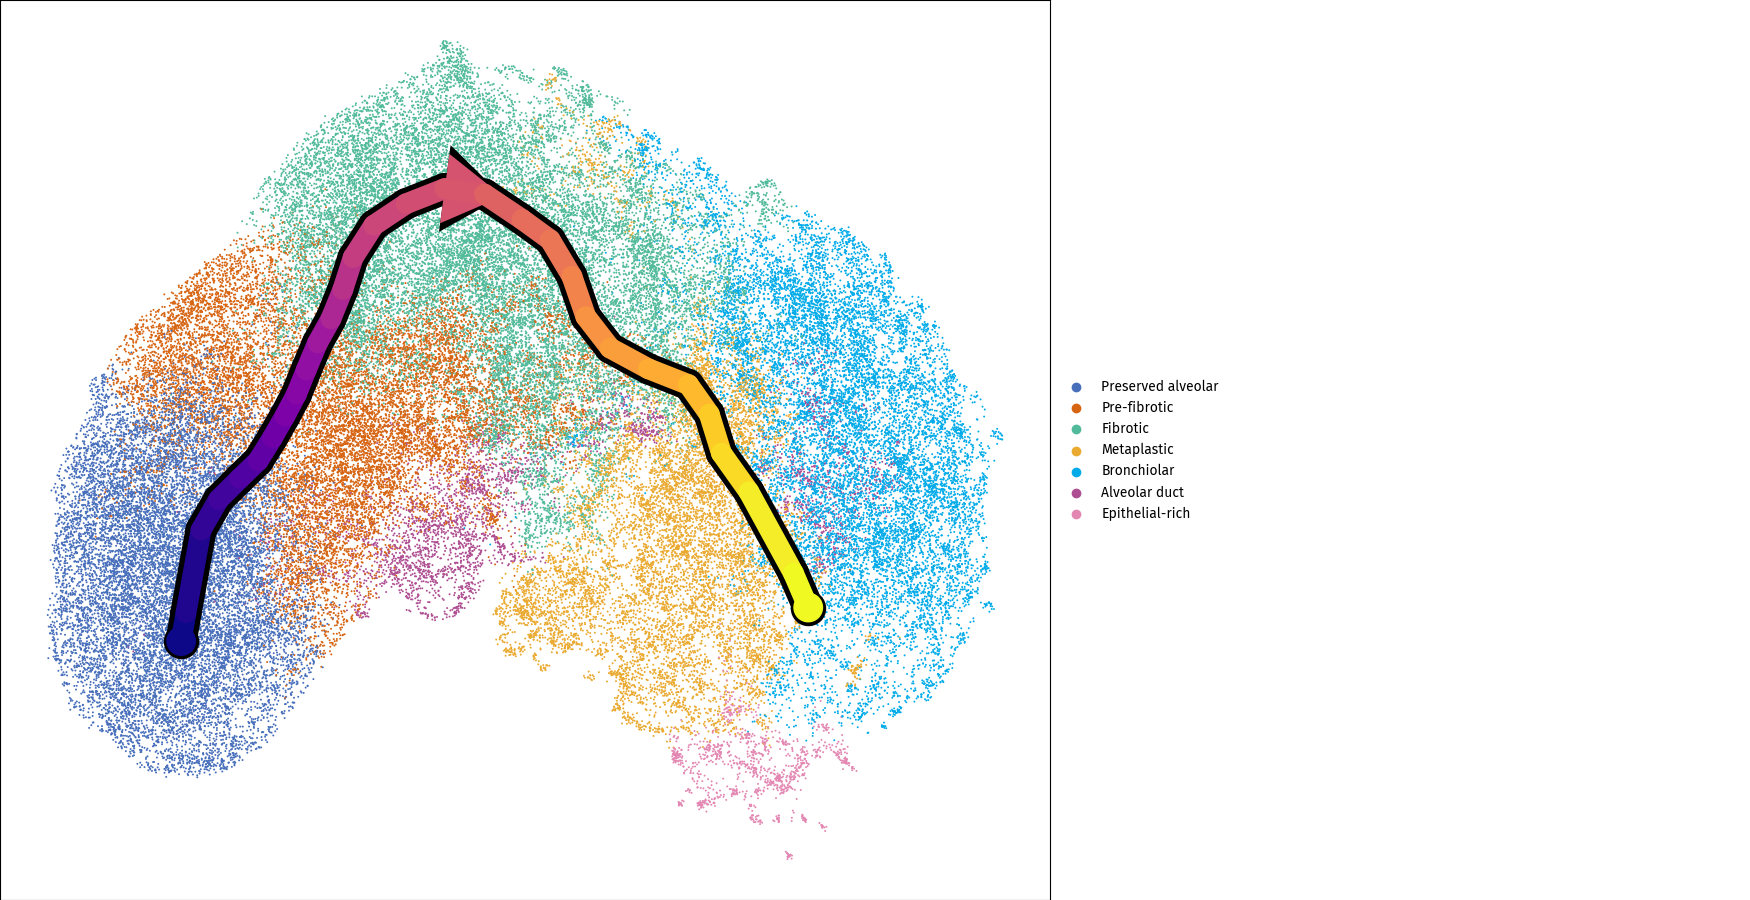

In [8]:
fig, ax = plt.subplots(figsize=(3*3.5/0.6,3*3))
fig.subplots_adjust(left=0, right=0.6, top=1, bottom=0)
scf.pl.trajectory(n_adata,basis="umap", arrows=True, arrow_offset=1, scale_path=3, color_cells="EcNP", ax=ax, s=8, cmap_seg="plasma" )
plt.title("")
plt.axis("off")
ax.legend(title="", loc='upper left', bbox_to_anchor=(0.92, 0.95), edgecolor="white", labelcolor="black", markerscale=5, fontsize=36, handletextpad=0.05)
values = n_adata.obs["t"]
norm = matplotlib.colors.Normalize(vmin=values.min(), vmax=values.max())
sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
cbar_ax = fig.add_axes([0.6, 0.15, 0.25, 0.04])
cbar = fig.colorbar(sm, cax=cbar_ax, ticks=[0.0, 0.5, 1.0], orientation="horizontal")
cbar.ax.set_xticklabels(['0.0', "0.5", "1.0"], fontsize=26)
cbar.ax.set_title("Continuum position", fontsize=30)

# arrow head size
ax.get_children()[9].headwidth=ax.get_children()[10].headwidth
ax.get_children()[9].scale=ax.get_children()[9].scale*0.82
ax.get_children()[9].set_offsets([[ax.get_children()[9].get_offsets()[0][0]-0.05,ax.get_children()[9].get_offsets()[0][1]-0.01]])

# start/end dot size
ax.get_children()[11].set(sizes=np.array([2000]))
ax.get_children()[13].set(sizes=np.array([1400]))

fig.savefig(f"{REV_PATH}EcNP_umap_cPosition_trajectory_allclass.png", dpi=100, format="png", bbox_inches=None)

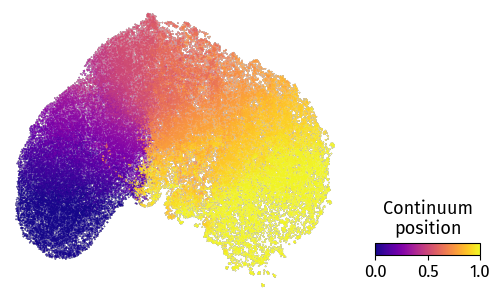

In [9]:
fig, ax = plt.subplots(figsize=(3.5/0.7,3))
fig.subplots_adjust(left=0, right=0.7, bottom=0, top=1)
sc.pl.umap(n_adata, color="t", cmap="plasma", s=5, outline_width=(0,0), add_outline=True, ax=ax, colorbar_loc=None, show=False)
ax.axis("off")
ax.set_title("")

values = n_adata.obs["t"]
norm = matplotlib.colors.Normalize(vmin=values.min(), vmax=values.max())
sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
cbar_ax = fig.add_axes([0.75, 0.15, 0.21, 0.04])
cbar = fig.colorbar(sm, cax=cbar_ax, ticks=[0.0, 0.5, 1.0], orientation="horizontal")
cbar.ax.set_xticklabels(['0.0', "0.5", "1.0"], fontsize=12)
cbar.ax.set_title("Continuum\nposition", fontsize=13)
plt.show()

plt.savefig(f"{REV_PATH}EcNP_umap_cPosition_gradation_allclass.png", dpi=500, format="png", bbox_inches=None)

In [10]:
all_cp = n_adata.obs[["t"]].rename(columns={"t": "all_cp"})

In [11]:
ori_df = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")
ori_cp = ori_df[["C_position"]].copy().rename(columns={"C_position": "ori_cp"})

In [12]:
df = pd.merge(all_cp, ori_cp, left_index=True, right_index=True, how="left")

In [13]:
df_common = df.dropna(subset=["ori_cp"]).copy()

rho, p_rho = spearmanr(df_common["ori_cp"], df_common["all_cp"])
tau, p_tau = kendalltau(df_common["ori_cp"], df_common["all_cp"])
r, p_r = pearsonr(df_common["ori_cp"], df_common["all_cp"])

mae = np.mean(np.abs(df_common["all_cp"] - df_common["ori_cp"]))
median_ae = np.median(np.abs(df_common["all_cp"] - df_common["ori_cp"]))

print(f"n = {len(df_common):,}")
print(f"Spearman rho = {rho:.4f}, p = {p_rho:.3g}")
print(f"Kendall tau = {tau:.4f}, p = {p_tau:.3g}")
print(f"Pearson r = {r:.4f}, p = {p_r:.3g}")
print(f"MAE = {mae:.4f}")
print(f"Median AE = {median_ae:.4f}")

n = 61,331
Spearman rho = 0.9969, p = 0
Kendall tau = 0.9634, p = 0
Pearson r = 0.9964, p = 0
MAE = 0.0317
Median AE = 0.0295


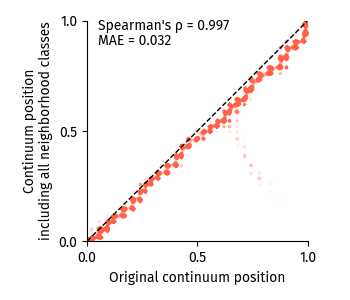

In [15]:
fig, ax = plt.subplots(figsize=(3.5, 3))

ax.scatter(
    df_common["ori_cp"],
    df_common["all_cp"],
    s=3,
    c="tomato",
    alpha=0.01
)

ax.plot([0, 1], [0, 1], ls="--", lw=1, c="black")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_yticks([0.0, 0.5, 1.0])
ax.set_xlabel("Original continuum position")
ax.set_ylabel("Continuum position\nincluding all neighborhood classes")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.text(s=f"Spearman's ρ = {rho:.3f}", x=0.05, y=.95, ha="left", va="bottom")
ax.text(s=f"MAE = {mae:.3f}", x=0.05, y=.94, ha="left", va="top")
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(f"{REV_PATH}ori_all_scatter.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [16]:
df_common["abs_delta"] = abs(df_common["all_cp"] - df_common["ori_cp"])
outlier_ids = df_common.index[df_common["abs_delta"] > 0.2]

In [22]:
plot_df = df.join(n_adata.obs[["EcNP"]], how="left")
plot_df["EcNP"]=pd.Categorical(plot_df["EcNP"], ordered=True, 
                               categories=["Preserved alveolar", "Pre-fibrotic", "Fibrotic", "Metaplastic", "Bronchiolar", "Alveolar duct", "Epithelial-rich"])


In [18]:
ori_df["EcNP"]=pd.Categorical(ori_df["EcNP"], ordered=True, 
                               categories=["Preserved alveolar", "Pre-fibrotic", "Fibrotic", "Metaplastic"])


/tmp/ipykernel_874/1891012356.py:5: UserWarning: The palette list has more values (7) than needed (4), which may not be intended.
  sns.violinplot(


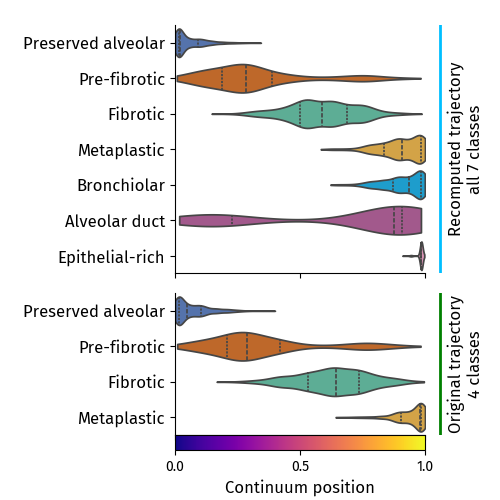

In [23]:
fig, (ax1, ax2) = plt.subplots(2,1,figsize=(5, 5), height_ratios=(7,4))
fig.subplots_adjust(left=0.35, right=0.85, top=0.95, bottom=0.13, hspace=0.1)

for ax, pl_d, x in zip([ax1, ax2], [plot_df, ori_df], ["all_cp", "C_position"]):
    sns.violinplot(
        data=pl_d,
        y="EcNP",
        hue="EcNP",
        x=x,
        inner="quartile",
        cut=0,
        density_norm="width",
        bw_adjust=2,
        palette=n_adata.uns["EcNP_colors"].tolist(),
        ax=ax,
        legend=False
    )

    ax.set_xlim(0, 1)
    ax.set_ylabel("")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=12)
    ax.tick_params(axis="x", labelsize=11)

ax1.set_xticks([0, 0.5, 1], labels=[])
ax2.set_xticks([0, 0.5, 1], labels=[])
ax1.set_xlabel("")
ax2.set_xlabel("")

ax11 = fig.add_axes([0.85, ax1.get_position().y0, 0.15, ax1.get_position().height])
ax22 = fig.add_axes([0.85, ax2.get_position().y0, 0.15, ax2.get_position().height])
ax11.axvline(x=0.2, c="deepskyblue", lw=2)
ax22.axvline(x=0.2, c="green", lw=2)
ax11.axis("off")
ax22.axis("off")
ax11.text(s="Recomputed trajectory\nall 7 classes", x=0.3, y=0.5, rotation=90, va="center", ha="left", multialignment="center", fontsize=12)
ax22.text(s="Original trajectory\n4 classes", x=0.3, y=0.5, rotation=90, va="center", ha="left", multialignment="center", fontsize=12)

norm_cp = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm_cp)
ax_cp = fig.add_axes([0.35, 0.1, ax1.get_position().width, 0.03])
cp_bar = fig.colorbar(sm_cp, cax=ax_cp, ticks=[0, 0.5, 1], orientation="horizontal")
ax_cp.set_xlabel("Continuum position", fontsize=12)

fig.savefig(f"{REV_PATH}ori_all_violin.png", dpi=500, format="png", bbox_inches=None)
plt.show()

# Branching trajectory analysis

In [17]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib
import gc
import pandas as pd
from scipy.stats import spearmanr
import scFates as scf
import seaborn as sns
from Xenium_5K_IPF_constants import EPITHELIAL_SUBTYPE, WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
p_time_cmap = "plasma"

REV_PATH=f"{WORK_PATH}Revision/104/"

In [42]:
def summarize_tree_result(
    adata,
    config,
    seed,
    main_segments,
    ori_cp_col="C_position",
    ecnp_col="EcNP"
):
    graph = adata.uns["graph"]
    pp_seg = graph["pp_seg"].copy()

    # segment情報はadataから取得
    pp_seg["n"] = pd.to_numeric(pp_seg["n"]).astype(int)
    pp_seg["d"] = pd.to_numeric(pp_seg["d"]).astype(float)

    all_segments = set(pp_seg["n"])
    main_segments = set(main_segments)
    side_segments = all_segments - main_segments

    # ----------------------
    # topology
    # ----------------------
    n_tips = len(graph["tips"])
    n_forks = len(graph["forks"])

    # ----------------------
    # branch length
    # ----------------------
    total_length = pp_seg["d"].sum()

    main_length = pp_seg.loc[
        pp_seg["n"].isin(main_segments),
        "d"
    ].sum()

    side_length = total_length - main_length

    # ----------------------
    # cell assignment
    # ----------------------
    cell_seg = pd.to_numeric(
        adata.obs["seg"].astype(str),
        errors="coerce"
    )

    main_mask = cell_seg.isin(main_segments)
    side_mask = cell_seg.isin(side_segments)

    # ----------------------
    # side branch composition
    # ----------------------
    if side_mask.sum() > 0:
        side_fibrotic_fraction = (
            adata.obs.loc[side_mask, ecnp_col] == "Fibrotic"
        ).mean()
    else:
        side_fibrotic_fraction = np.nan

    # ----------------------
    # original continuumとの一致
    # ----------------------
    valid = (
        main_mask
        & adata.obs[ori_cp_col].notna()
        & adata.obs["t"].notna()
    )

    rho_main = spearmanr(
        adata.obs.loc[valid, ori_cp_col],
        adata.obs.loc[valid, "t"]
    ).statistic

    # ----------------------
    # main backbone上のECNP順序
    # ----------------------
    median_t = (
        adata.obs.loc[main_mask]
        .groupby(ecnp_col, observed=True)["t"]
        .median()
    )

    result = {
        "config": config,
        "seed": seed,
        "n_tips": n_tips,
        "n_forks": n_forks,

        "total_tree_length": total_length,
        "main_backbone_length": main_length,
        "main_length_fraction": main_length / total_length,

        "side_length": side_length,
        "side_length_fraction": side_length / total_length,

        "main_cell_fraction": main_mask.mean(),
        "side_cell_fraction": side_mask.mean(),

        "side_fibrotic_fraction": side_fibrotic_fraction,

        "rho_main_vs_original": rho_main,

        "median_t_preserved": median_t.get(
            "Preserved alveolar", np.nan
        ),
        "median_t_prefibrotic": median_t.get(
            "Pre-fibrotic", np.nan
        ),
        "median_t_fibrotic": median_t.get(
            "Fibrotic", np.nan
        ),
        "median_t_metaplastic": median_t.get(
            "Metaplastic", np.nan
        ),
    }

    return pd.DataFrame([result])

In [2]:
cp_df = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [3]:
n_adata = sc.read_h5ad(f"{WORK_PATH}AnnData/EcNP.h5ad")
n_adata.obs["subtype"]=pd.Categorical(n_adata.obs["subtype"], categories=EPITHELIAL_SUBTYPE, ordered=True)

In [4]:
n_adata = n_adata[~n_adata.obs["EcNP"].isin(['Bronchiolar', 'Alveolar duct', "Epithelial-rich"])]

In [5]:
n_adata.obs["C_position"]=cp_df[["C_position"]]

/tmp/ipykernel_4359/1247994119.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_adata.obs["C_position"]=cp_df[["C_position"]]


In [ ]:
summary_list=[]

In [6]:
test_adata = n_adata.copy()

In [7]:
configs = [
    # Nodes sensitivity
    {"label": "N20",      "Nodes": 20, "lam": 0.1,  "mu": 1},
    {"label": "N30",      "Nodes": 30, "lam": 0.1,  "mu": 1},
    {"label": "N40",      "Nodes": 40, "lam": 0.1,  "mu": 1},
    {"label": "N50",      "Nodes": 50, "lam": 0.1,  "mu": 1},

    # lambda sensitivity
    {"label": "lam0.05",  "Nodes": 30, "lam": 0.05, "mu": 1},
    {"label": "lam0.2",   "Nodes": 30, "lam": 0.2,  "mu": 1},

    # mu sensitivity
    {"label": "mu0.5",    "Nodes": 30, "lam": 0.1,  "mu": 0.5},
    {"label": "mu2",      "Nodes": 30, "lam": 0.1,  "mu": 2},
]

In [303]:
config = configs[7]
config["label"]

'mu2'

In [304]:
# scFates branching
scf.tl.tree(test_adata, Nodes=config["Nodes"], use_rep="X_pca", ndims_rep=2, method="epg", epg_lambda=config["lam"], epg_mu=config["mu"])

inferring a principal tree --> parameters used 
    30 principal points, mu = 2, lambda = 0.1
    finished (0:00:20) --> added 
    .uns['epg'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


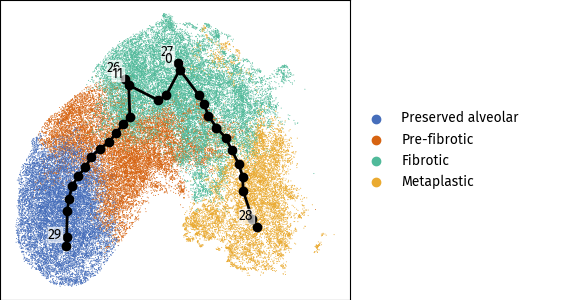

In [305]:
fig, ax = plt.subplots(figsize=(3.5/0.6,3))
fig.subplots_adjust(left=0, right=0.6, top=1, bottom=0)
scf.pl.graph(test_adata,basis="umap", color_cells="EcNP", s=2, ax=ax)
for obj in ax.get_children():
    if hasattr(obj, "get_text"):
        obj.set_fontsize(12)
ax.set_title("")
ax.axis("off")
fig.text(s=config["label"], x=0.95, y=0.05, va="bottom", ha="right", c="black", fontsize=20)
ax.legend(title="", loc='upper left', bbox_to_anchor=(0.92, 0.98), edgecolor="white", labelcolor="black", markerscale=1.5, fontsize=13, title_fontsize=13, handletextpad=0.05)
plt.savefig(f"{REV_PATH}104_EcNP_umap_cPosition_branching_{config["label"]}.png", dpi=500, format="png", bbox_inches=None)

In [306]:
tip_dict ={
    "N20": 4,
    "N30": 25,
    "N40": 36,
    "N50": 48,
    "lam0.05": 27,
    "lam0.2": 29,
    "mu0.5":25,
    "mu2":29
}


In [307]:
scf.tl.root(test_adata, tip_dict[config["label"]])

node 29 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [324]:
seed = 2

In [325]:
scf.tl.pseudotime(test_adata,n_jobs=20,n_map=20,seed=seed)

projecting cells onto the principal graph
    mappings: 100%|█████████████████████████████████████████████████████████████████████| 20/20 [00:36<00:00,  1.80s/it]
    finished (0:00:45) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [326]:
# max_min scaling
t = test_adata.obs["t"].values
test_adata.obs["t"] = (t - np.min(t)) / (np.max(t) - np.min(t))

<function matplotlib.pyplot.show(block=None)>

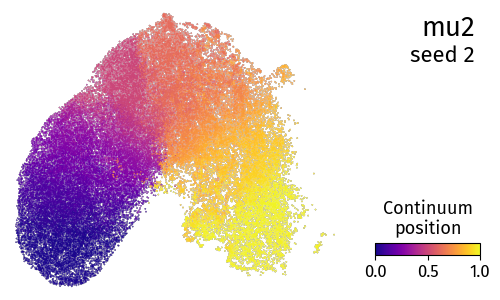

In [327]:
fig, ax = plt.subplots(figsize=(3.5/0.7,3))
fig.subplots_adjust(left=0, right=0.7, bottom=0, top=1)
sc.pl.umap(test_adata, color="t", cmap=p_time_cmap, s=5, outline_width=(0,0), add_outline=True, ax=ax, colorbar_loc=None, show=False)
ax.axis("off")
ax.set_title("")

values = test_adata.obs["t"]
norm = matplotlib.colors.Normalize(vmin=values.min(), vmax=values.max())
sm = plt.cm.ScalarMappable(cmap=p_time_cmap, norm=norm)
cbar_ax = fig.add_axes([0.75, 0.15, 0.21, 0.04])
cbar = fig.colorbar(sm, cax=cbar_ax, ticks=[0.0, 0.5, 1.0], orientation="horizontal")
cbar.ax.set_xticklabels(['0.0', "0.5", "1.0"], fontsize=12)
cbar.ax.set_title("Continuum\nposition", fontsize=13)

fig.text(s=config["label"], x=0.95, y=0.95, va="top", ha="right", c="black", fontsize=20)
fig.text(s=f"seed {seed}", x=0.95, y=0.85, va="top", ha="right", c="black", fontsize=16)
plt.savefig(f"{REV_PATH}104_EcNP_umap_cPosition_gradation_{config["label"]}_s{seed}.png", dpi=500, format="png", bbox_inches=None)
plt.show

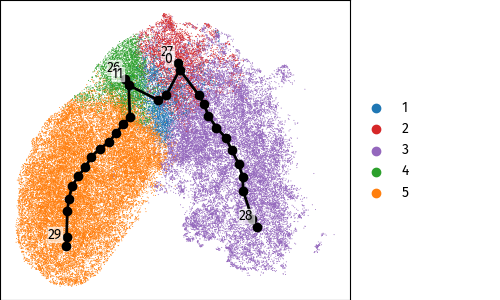

,n,from,to,d
1,1,11,0,4.135574
2,2,0,27,1.251978
3,3,0,28,12.903360
4,4,11,26,1.127771
5,5,29,11,16.061265


In [328]:
# check main branch
fig, ax = plt.subplots(figsize=(3.5/0.7,3))
fig.subplots_adjust(left=0, right=0.7, bottom=0, top=1)
scf.pl.graph(test_adata,basis="umap", color_cells="seg", s=2, ax=ax)
ax.axis("off")
ax.set_title("")

fig.text(s=config["label"], x=0.95, y=0.95, va="top", ha="right", c="black", fontsize=20)
fig.text(s=f"seed {seed}", x=0.95, y=0.85, va="top", ha="right", c="black", fontsize=16)
plt.savefig(f"{REV_PATH}104_EcNP_umap_cPosition_seg_{config["label"]}_s{seed}.png", dpi=500, format="png", bbox_inches=None)


test_adata.uns["graph"]["pp_seg"]

In [329]:
main_segs = {
    "N20":[3,2],
    "N30":[4,1,3],
    "N40":[4,1,3],
    "N50": [6,4,7,1,3],
    "lam0.05": [9,6,4,1,3],
    "lam0.2": [2,1,3],
    "mu0.5":[4,1,3],
    "mu2":[5,1,3]
}

In [330]:
summary = summarize_tree_result(
    test_adata,
    config=config["label"],
    seed = seed,
    main_segments=main_segs[config["label"]]
)
summary_list.append(summary)

In [331]:
# repeat
summary_df = pd.concat(
    summary_list,
    ignore_index=True
)

summary_df

,config,seed,n_tips,n_forks,total_tree_length,main_backbone_length,main_length_fraction,side_length,side_length_fraction,main_cell_fraction,side_cell_fraction,side_fibrotic_fraction,rho_main_vs_original,median_t_preserved,median_t_prefibrotic,median_t_fibrotic,median_t_metaplastic
0,N20,2,3,1,31.535507,30.143358,0.955855,1.392149,0.044145,0.907127,0.092873,0.979986,0.995976,0.029422,0.311123,0.679999,0.973788
1,N20,0,3,1,31.535507,30.143358,0.955855,1.392149,0.044145,0.907143,0.092857,0.979631,0.995989,0.029422,0.311123,0.679999,0.973789
2,N20,1,3,1,31.535507,30.143358,0.955855,1.392149,0.044145,0.907062,0.092938,0.979825,0.995986,0.029422,0.311123,0.679999,0.973789
3,N30,0,4,2,35.171813,32.842477,0.933773,2.329336,0.066227,0.875446,0.124554,0.930881,0.997946,0.061480,0.311692,0.674183,0.943056
4,N30,1,4,2,35.171813,32.842477,0.933773,2.329336,0.066227,0.875185,0.124815,0.930895,0.997948,0.061725,0.311836,0.674251,0.943048
5,N30,2,4,2,35.171813,32.842477,0.933773,2.329336,0.066227,0.875039,0.124961,0.932933,0.997959,0.061562,0.311839,0.674251,0.942968
6,N40,0,4,2,37.159282,34.370446,0.924949,2.788836,0.075051,0.870962,0.129038,0.944655,0.997211,0.067987,0.295966,0.673206,0.933484
7,N40,1,4,2,37.159282,34.370446,0.924949,2.788836,0.075051,0.871060,0.128940,0.944613,0.997208,0.067649,0.295721,0.672974,0.933452
8,N40,2,4,2,37.159282,34.370446,0.924949,2.788836,0.075051,0.871158,0.128842,0.944698,0.997215,0.067362,0.295631,0.672910,0.933309
9,N50,0,6,4,41.719972,35.982962,0.862488,5.737010,0.137512,0.806476,0.193524,0.550678,0.996947,0.075203,0.298206,0.684584,0.938458


In [332]:
summary_df.to_csv(f"{REV_PATH}branching_test_results.csv", index=False)

In [2]:
summary_df= pd.read_csv(f"{REV_PATH}branching_test_results.csv")

In [3]:
summary_config = (
    summary_df
    .groupby("config")
    .agg(
        n_runs=("seed", "count"),

        tips_min=("n_tips", "min"),
        tips_max=("n_tips", "max"),

        forks_min=("n_forks", "min"),
        forks_max=("n_forks", "max"),

        main_length_fraction_median=(
            "main_length_fraction", "median"
        ),
        main_length_fraction_min=(
            "main_length_fraction", "min"
        ),
        main_length_fraction_max=(
            "main_length_fraction", "max"
        ),

        side_cell_fraction_median=(
            "side_cell_fraction", "median"
        ),
        side_cell_fraction_min=(
            "side_cell_fraction", "min"
        ),
        side_cell_fraction_max=(
            "side_cell_fraction", "max"
        ),

        side_fibrotic_fraction_median=(
            "side_fibrotic_fraction", "median"
        ),
        side_fibrotic_fraction_min=(
            "side_fibrotic_fraction", "min"
        ),
        side_fibrotic_fraction_max=(
            "side_fibrotic_fraction", "max"
        ),

        rho_median=(
            "rho_main_vs_original", "median"
        ),
        rho_min=(
            "rho_main_vs_original", "min"
        ),
        rho_max=(
            "rho_main_vs_original", "max"
        ),
    )
    .reset_index()
)

summary_config

,config,n_runs,tips_min,tips_max,forks_min,forks_max,main_length_fraction_median,main_length_fraction_min,main_length_fraction_max,side_cell_fraction_median,side_cell_fraction_min,side_cell_fraction_max,side_fibrotic_fraction_median,side_fibrotic_fraction_min,side_fibrotic_fraction_max,rho_median,rho_min,rho_max
0,N20,3,3,3,1,1,0.955855,0.955855,0.955855,0.092873,0.092857,0.092938,0.979825,0.979631,0.979986,0.995986,0.995976,0.995989
1,N30,3,4,4,2,2,0.933773,0.933773,0.933773,0.124815,0.124554,0.124961,0.930895,0.930881,0.932933,0.997948,0.997946,0.997959
2,N40,3,4,4,2,2,0.924949,0.924949,0.924949,0.128940,0.128842,0.129038,0.944655,0.944613,0.944698,0.997211,0.997208,0.997215
3,N50,3,6,6,4,4,0.862488,0.862488,0.862488,0.193524,0.193393,0.194078,0.550678,0.548937,0.550965,0.996947,0.996942,0.996952
4,lam0.05,3,6,6,4,4,0.835349,0.835349,0.835349,0.210383,0.209959,0.210432,0.513862,0.513756,0.514954,0.996707,0.996701,0.996709
5,lam0.2,3,3,3,1,1,0.966717,0.966717,0.966717,0.091944,0.091927,0.091960,0.989360,0.989358,0.989362,0.996441,0.996423,0.996455
6,mu0.5,3,4,4,2,2,0.932831,0.932831,0.932831,0.106243,0.105705,0.106700,0.940147,0.938454,0.940403,0.997873,0.997869,0.997883
7,mu2,3,4,4,2,2,0.932927,0.932927,0.932927,0.127537,0.127423,0.127619,0.919074,0.919002,0.921043,0.997845,0.997836,0.997861


In [4]:
summary_df["class_order_preserved"] = (
    (summary_df["median_t_preserved"] <
     summary_df["median_t_prefibrotic"])
    &
    (summary_df["median_t_prefibrotic"] <
     summary_df["median_t_fibrotic"])
    &
    (summary_df["median_t_fibrotic"] <
     summary_df["median_t_metaplastic"])
)

summary_df[
    [
        "config",
        "seed",
        "class_order_preserved",
        "median_t_preserved",
        "median_t_prefibrotic",
        "median_t_fibrotic",
        "median_t_metaplastic"
    ]
]

,config,seed,class_order_preserved,median_t_preserved,median_t_prefibrotic,median_t_fibrotic,median_t_metaplastic
0,N20,2,True,0.029422,0.311123,0.679999,0.973788
1,N20,0,True,0.029422,0.311123,0.679999,0.973789
2,N20,1,True,0.029422,0.311123,0.679999,0.973789
3,N30,0,True,0.061480,0.311692,0.674183,0.943056
4,N30,1,True,0.061725,0.311836,0.674251,0.943048
5,N30,2,True,0.061562,0.311839,0.674251,0.942968
6,N40,0,True,0.067987,0.295966,0.673206,0.933484
7,N40,1,True,0.067649,0.295721,0.672974,0.933452
8,N40,2,True,0.067362,0.295631,0.672910,0.933309
9,N50,0,True,0.075203,0.298206,0.684584,0.938458


In [5]:
x

NameError: name 'x' is not defined

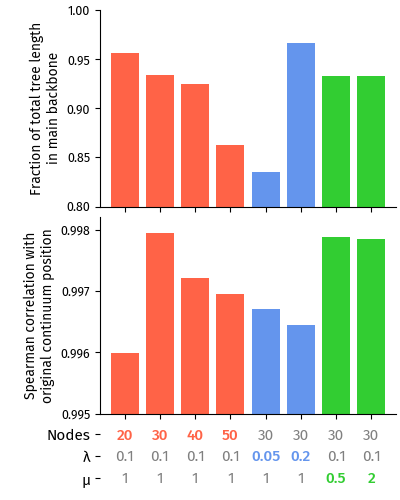

In [6]:
order = ["N20", "N30", "N40", "N50", "lam0.05", "lam0.2", "mu0.5", "mu2"]
colors = ["tomato"]*4+["cornflowerblue"]*2+["limegreen"]*2
n_tx = ["20", "30", "40", "50", "30", "30", "30", "30"]
l_tx = ["0.1", "0.1", "0.1", "0.1", "0.05", "0.2", "0.1", "0.1"]
m_tx = ["1", "1", "1", "1", "1", "1", "0.5", "2"]

df_plot = (
    summary_config
    .set_index("config")
    .loc[order]
    .reset_index()
)

x = np.arange(len(df_plot))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1,figsize=(4, 5), height_ratios=(9,9,3))
fig.subplots_adjust(left=0.25, right=0.99, top=0.98, bottom=0.02, hspace=0.07)
ax1.bar(x, df_plot["main_length_fraction_median"], color=colors)

ax1.set_xticks(x, labels=[])
ax1.set_xlim(-0.7, len(x)-0.3)
ax1.set_ylim(0.8, 1.0)
ax1.set_yticks([0.80, 0.85, 0.90, 0.95,  1.0])
ax1.tick_params("y", labelsize=9)
ax1.set_ylabel("Fraction of total tree length\nin main backbone")
ax1.set_xlabel("")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax2.bar(x, df_plot["rho_median"], color=colors)

ax2.set_xticks(x, labels=[])
ax2.set_xlim(-0.7, len(x)-0.3)
ax2.set_ylim(0.995, 0.9982)
ax2.set_yticks([0.995, 0.996, 0.997, 0.998])
ax2.tick_params("y", labelsize=9)
ax2.set_ylabel("Spearman correlation with\noriginal continuum position")
ax2.set_xlabel("")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)


ax3.set_xticks([])
ax3.set_xlim(-0.7, len(x)-0.3)
ax3.set_ylim(0,3)
ax3.set_yticks([0.55, 1.55, 2.55], ["μ", "λ", "Nodes"], fontsize=11)
# ax3.set_xticks([])
for spn in ["left", "right", "top", "bottom"]:
    ax3.spines[spn].set_visible(False)

for p, (n, l, m) in enumerate(zip(n_tx, l_tx, m_tx)):
    c = colors[p]
    if p < 4:
        ax3.text(s=n, x=p, y=2.5, fontsize=11, ha="center", va="center", c=c, fontweight=500)
        ax3.text(s=l, x=p, y=1.5, fontsize=11, ha="center", va="center", c="grey")
        ax3.text(s=m, x=p, y=0.5, fontsize=11, ha="center", va="center", c="grey")
    elif p < 6:
        ax3.text(s=n, x=p, y=2.5, fontsize=11, ha="center", va="center", c="grey")
        ax3.text(s=l, x=p, y=1.5, fontsize=11, ha="center", va="center", c=c, fontweight=500)
        ax3.text(s=m, x=p, y=0.5, fontsize=11, ha="center", va="center", c="grey")
    else:
        ax3.text(s=n, x=p, y=2.5, fontsize=11, ha="center", va="center", c="grey")
        ax3.text(s=l, x=p, y=1.5, fontsize=11, ha="center", va="center", c="grey")
        ax3.text(s=m, x=p, y=0.5, fontsize=11, ha="center", va="center", c=c, fontweight=500)

plt.savefig(f"{REV_PATH}104_all_configs.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [8]:

df_source = (
    summary_config
    .set_index("config")
    .loc[order, ["main_length_fraction_median", "rho_median"]]
    .reset_index()
    .rename(columns={
        "config": "Configuration",
        "main_length_fraction_median": "Main_backbone_fraction_median",
        "rho_median": "Spearman_rho_median"
    })
)

df_source.insert(1, "Nodes", [int(x) for x in n_tx])
df_source.insert(2, "Lambda", [float(x) for x in l_tx])
df_source.insert(3, "Mu", [float(x) for x in m_tx])

# Excel出力
df_source.to_csv(f"{REV_PATH}104_all_configs_source_data.csv", index=True)